# EDA de la jointure des matchs de football

Cette exploration suit la démarche du notebook Toyota, adaptée à notre contexte. Elle avance dans un ordre simple :

1. **Qu'ai-je ?** Comprendre la taille, les observations, les variables et leurs types.
2. **Puis-je faire confiance aux données ?** Contrôler les valeurs manquantes, les doublons, les catégories, les valeurs impossibles et les dates.
3. **Que racontent ces variables ?** Explorer les distributions, le temps, les groupes et les relations entre variables.

Chaque partie se termine par une réponse explicite à la question posée.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.style.use("seaborn-v0_8-whitegrid")

data_dir = Path("../data")
if not data_dir.exists():
    data_dir = Path("data")

train = pd.read_csv(data_dir / "train.csv", low_memory=False)
scores = pd.read_csv(data_dir / "train_target_and_scores.csv")

df = train.merge(
    scores[["id", "score"]],
    on="id",
    how="left",
    validate="one_to_one",
)

# Table enrichie réservée à l'EDA : le DataFrame df reste la jointure brute.
eda = df.copy()
eda["match_date_parsed"] = pd.to_datetime(eda["match_date"], errors="coerce")
goals = eda["score"].astype("string").str.extract(r"^(\d+)\s*-\s*(\d+)$")
eda["home_goals"] = pd.to_numeric(goals[0], errors="coerce")
eda["away_goals"] = pd.to_numeric(goals[1], errors="coerce")
eda["total_goals"] = eda["home_goals"] + eda["away_goals"]

home_history_goals = [f"home_team_history_goal_{i}" for i in range(1, 11)]
away_history_goals = [f"away_team_history_goal_{i}" for i in range(1, 11)]
home_history_ratings = [f"home_team_history_rating_{i}" for i in range(1, 11)]
away_history_ratings = [f"away_team_history_rating_{i}" for i in range(1, 11)]
eda["home_recent_goals_mean"] = eda[home_history_goals].mean(axis=1)
eda["away_recent_goals_mean"] = eda[away_history_goals].mean(axis=1)
eda["home_recent_rating_mean"] = eda[home_history_ratings].mean(axis=1)
eda["away_recent_rating_mean"] = eda[away_history_ratings].mean(axis=1)
eda["recent_rating_difference"] = eda["home_recent_rating_mean"] - eda["away_recent_rating_mean"]

# Partie 1 — Qu'ai-je ?

On commence comme dans le notebook Toyota : observer la table avant de chercher à l'expliquer. `shape`, `head`, `sample`, `columns`, `info` et `describe` répondent chacun à une question précise.

## 1.1 Dimensions et structure

In [2]:
print(f"La jointure contient {df.shape[0]:,} lignes et {df.shape[1]} colonnes.")
df.shape

La jointure contient 110,938 lignes et 191 colonnes.


(110938, 191)

### À quoi ressemble une observation ?

In [3]:
df.head()

,id,target,home_team_name,away_team_name,match_date,league_name,league_id,is_cup,home_team_coach_id,away_team_coach_id,home_team_history_match_date_1,home_team_history_match_date_2,home_team_history_match_date_3,home_team_history_match_date_4,home_team_history_match_date_5,...,away_team_history_coach_7,away_team_history_coach_8,away_team_history_coach_9,away_team_history_coach_10,away_team_history_league_id_1,away_team_history_league_id_2,away_team_history_league_id_3,away_team_history_league_id_4,away_team_history_league_id_5,away_team_history_league_id_6,away_team_history_league_id_7,away_team_history_league_id_8,away_team_history_league_id_9,away_team_history_league_id_10,score
0,11906497,away,Newell's Old Boys,River Plate,2019-12-01 00:45:00,Superliga,636,False,"468,196.00","468,200.00",2019-11-26 00:10:00,2019-11-10 18:30:00,2019-11-03 18:30:00,2019-10-29 22:10:00,2019-10-19 20:45:00,...,"468,200.00","468,200.00","468,200.00","468,200.00","1,122.00",642.00,636.00,636.00,636.00,"1,122.00",636.00,642.00,636.00,"1,122.00",2-3
1,11984383,home,Real Estelí,Deportivo Las Sabanas,2019-12-01 01:00:00,Primera Division,752,False,"516,788.00","22,169,161.00",2019-11-27 21:00:00,2019-11-24 01:00:00,2019-11-10 01:00:00,2019-11-02 21:30:00,2019-10-27 01:00:00,...,"22,169,161.00","22,169,161.00","22,169,161.00","22,169,161.00",752.00,752.00,752.00,752.00,752.00,752.00,752.00,752.00,752.00,752.00,1-0
2,11983301,draw,UPNFM,Marathón,2019-12-01 01:00:00,Liga Nacional,734,False,"2,510,608.00","456,313.00",2019-11-28 01:15:00,2019-11-21 01:30:00,2019-11-03 21:30:00,2019-10-27 01:00:00,2019-10-20 22:00:00,...,"456,313.00","456,313.00","456,313.00","456,313.00",734.00,734.00,734.00,734.00,734.00,734.00,734.00,734.00,734.00,734.00,2-2
3,11983471,away,León,Morelia,2019-12-01 01:00:00,Liga MX,743,False,"1,552,508.00","465,797.00",2019-11-28 01:00:00,2019-11-23 03:10:00,2019-11-10 03:00:00,2019-11-04 02:00:00,2019-11-01 03:00:00,...,"465,797.00","465,797.00","465,797.00","465,797.00",743.00,743.00,743.00,743.00,743.00,743.00,743.00,743.00,746.00,743.00,1-2
4,11883005,home,Cobán Imperial,Iztapa,2019-12-01 01:00:00,Liga Nacional,705,False,"429,958.00","426,870.00",2019-11-27 18:00:00,2019-11-24 01:00:00,2019-11-10 02:00:00,2019-11-03 01:00:00,2019-10-27 20:30:00,...,"426,870.00","37,261,558.00","37,261,558.00","37,261,558.00",705.00,705.00,705.00,705.00,705.00,705.00,705.00,705.00,705.00,705.00,1-0


In [4]:
df.sample(5, random_state=42)

,id,target,home_team_name,away_team_name,match_date,league_name,league_id,is_cup,home_team_coach_id,away_team_coach_id,home_team_history_match_date_1,home_team_history_match_date_2,home_team_history_match_date_3,home_team_history_match_date_4,home_team_history_match_date_5,...,away_team_history_coach_7,away_team_history_coach_8,away_team_history_coach_9,away_team_history_coach_10,away_team_history_league_id_1,away_team_history_league_id_2,away_team_history_league_id_3,away_team_history_league_id_4,away_team_history_league_id_5,away_team_history_league_id_6,away_team_history_league_id_7,away_team_history_league_id_8,away_team_history_league_id_9,away_team_history_league_id_10,score
97074,16725486,home,Sochi,Tambov,2021-03-19 16:00:00,Premier League,486,False,"3,181,403.00","37,346,856.00",2021-03-14 16:00:00,2021-03-06 16:00:00,2021-02-27 16:00:00,2021-02-21 14:00:00,2021-02-14 10:00:00,...,"37,346,856.00","37,346,856.00","37,346,856.00","37,346,856.00",486.00,486.00,486.00,492.00,486.00,486.00,486.00,486.00,486.00,486.00,5-0
64970,17646292,home,Palmeiras,Ceará,2020-11-11 19:30:00,Copa do Brasil,654,True,"2,511,092.00","456,033.00",2020-11-08 19:00:00,2020-11-05 22:00:00,2020-11-02 20:00:00,2020-10-29 22:00:00,2020-10-25 19:00:00,...,"456,033.00","456,033.00","456,033.00","456,033.00",648.00,654.00,648.00,654.00,648.00,"1,300.00",648.00,648.00,648.00,648.00,3-0
42183,14050261,home,VPS,EIF,2020-09-05 13:30:00,Ykkonen,295,False,"90,959.00","93,865.00",2020-08-30 14:00:00,2020-08-22 13:30:00,2020-08-15 13:00:00,2020-08-09 14:00:00,2020-08-05 15:30:00,...,"37,260,037.00","37,260,037.00","37,260,037.00","37,260,037.00",295.00,295.00,295.00,295.00,295.00,295.00,295.00,295.00,295.00,295.00,1-0
106616,17777655,home,Suwon Bluewings,Ulsan,2021-04-18 05:00:00,K-League 1,1034,False,"37,553,746.00","452,818.00",2021-04-14 10:00:00,2021-04-11 07:00:00,2021-04-07 10:30:00,2021-04-03 05:00:00,2021-03-21 07:30:00,...,"452,818.00","452,818.00","452,818.00","463,082.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,034.00","1,085.00",3-0
12826,11990331,home,Inter Allies,King Faisal,2020-01-31 15:30:00,Premier League,836,False,"473,364.00","37,252,510.00",2020-01-25 15:00:00,2020-01-15 15:00:00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,836.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4-2


In [5]:
df['league_name'].value_counts()

league_name
Premier League         5565
Club Friendlies        3724
Primera Division       2369
Super League           1530
3. Liga                1327
                       ... 
Play-offs 2/3             1
Trofeo Joan Gamper        1
4. Liga Division F        1
Copa Paraguay             1
National 3: Group L       1
Name: count, Length: 727, dtype: int64

In [9]:
df['league_name'].unique()

array(['Superliga', 'Primera Division', 'Liga Nacional', 'Liga MX',
       'Premiership', 'Japan Football League', 'J3-League', 'W-League',
       'A-League', 'Taiwan Football Premier League', 'First Division',
       'K-League Classic', 'Premier League',
       'Professional Football League', 'Super League',
       'Southeast Asian Games', 'Liga 1', '3. Lig: Group 3',
       'Liga 1 Women', 'Youth League', 'PrimaVera 1', 'Erste Liga',
       'Tercera - Group 4', 'Oberliga: Hamburg', '2. Lig: Kirmizi',
       '3. Lig: Group 2', 'Junioren Bundesliga', 'Segunda B - Group 4',
       'Parva Liga', 'Crystalbet Erovnuli Liga', '3. Lig: Group 1',
       '2. Lig: Beyaz', 'Tercera - Group 6', 'Tercera - Group 17',
       'Tercera - Group 7', 'Tercera - Group 13',
       'Primera Division Women', 'Tercera - Group 16', '1. Lig',
       'Tercera - Group 9', 'Segunda B - Group 3', 'Tercera - Group 2',
       '2. Division: Group B', 'Lig Bet', 'Tercera - Group 11',
       'Segunda B - Group 1', 'La 

In [13]:
equipes_uniques = pd.concat(
    [eda["home_team_name"], eda["away_team_name"]]
).dropna().unique()

print(f"Il y a {len(equipes_uniques):,} équipes uniques.")

Il y a 10,214 équipes uniques.


In [14]:
nombre_matchs_coupe = int(df["is_cup"].eq(True).sum())
print(f"Nombre de matchs joués en coupe : {nombre_matchs_coupe:,}")

Nombre de matchs joués en coupe : 9,081


### Quelles sont les variables ?

In [10]:
pd.DataFrame({"variable": df.columns, "type": df.dtypes.astype(str).values})

,variable,type
0,id,int64
1,target,object
2,home_team_name,object
3,away_team_name,object
4,match_date,object
...,...,...
186,away_team_history_league_id_7,float64
187,away_team_history_league_id_8,float64
188,away_team_history_league_id_9,float64
189,away_team_history_league_id_10,float64


### Quels sont les types ?

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110938 entries, 0 to 110937
Columns: 191 entries, id to score
dtypes: float64(162), int64(2), object(27)
memory usage: 161.7+ MB


In [12]:
df.dtypes.value_counts().rename_axis("type").to_frame("nombre_de_colonnes")

,nombre_de_colonnes
type,
float64,162
object,27
int64,2


### Premiers ordres de grandeur

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,"110,938.00","15,198,746.33","2,536,393.09","11,428,294.00","12,000,376.25","16,759,881.50","17,242,303.75","18,053,837.00"
league_id,"110,938.00",910.46,549.12,2.00,444.00,947.00,"1,293.00","2,039.00"
home_team_coach_id,"89,217.00","12,871,343.06","15,784,787.59",2.00,"459,612.00","1,552,728.00","32,431,162.00","37,568,493.00"
away_team_coach_id,"89,123.00","12,915,516.81","15,803,444.50",2.00,"459,565.00","1,552,806.00","32,795,385.50","37,568,466.00"
home_team_history_is_play_home_1,"109,779.00",0.31,0.46,0.00,0.00,0.00,1.00,1.00
...,...,...,...,...,...,...,...,...
away_team_history_league_id_6,"102,512.00",861.90,527.34,2.00,408.00,881.00,"1,267.00","2,039.00"
away_team_history_league_id_7,"101,071.00",853.44,524.22,2.00,399.00,860.00,"1,265.00","2,039.00"
away_team_history_league_id_8,"99,643.00",844.67,520.95,2.00,391.50,830.00,"1,263.00","2,039.00"
away_team_history_league_id_9,"98,176.00",837.68,517.65,2.00,387.00,821.00,"1,261.00","2,028.00"


## Réponse à la partie 1 — Qu'ai-je ?

RÉPONSE : nous avons une table de matchs de football enrichie par l'historique récent des deux équipes.
- 110,938 observations et 191 variables après la jointure.
- Une observation correspond à un match entre une équipe à domicile et une équipe à l'extérieur.
- Les variables décrivent l'identité du match, la compétition, les entraîneurs, le résultat et les dix matchs précédents de chaque équipe.
- La période observée va du 2019-12-01 au 2021-05-01.
- 727 ligues uniques
- 10214 équipes uniques
- 9081 matchs joués en coupe

# Partie 2 — Puis-je faire confiance aux données ?

Avant toute interprétation, on cherche les défauts susceptibles de fausser l'analyse ou le futur modèle.

## 2.1 Que manque-t-il ?

Les colonnes sont classées selon leur proportion de valeurs manquantes.

In [ ]:
missing_summary = pd.DataFrame({
    "valeurs_manquantes": df.isna().sum(),
    "pourcentage": 100 * df.isna().mean(),
}).query("valeurs_manquantes > 0").sort_values("pourcentage", ascending=False)

print(f"{len(missing_summary)} colonnes sur {df.shape[1]} contiennent au moins une valeur manquante.")
print(f"Le score manque pour {df['score'].isna().sum():,} match(s).")
display(missing_summary.head(30))

186 colonnes sur 191 contiennent au moins une valeur manquante.
Le score manque pour 0 match(s).


,valeurs_manquantes,pourcentage
away_team_history_coach_10,27129,24.45
home_team_history_coach_10,26653,24.03
away_team_history_coach_9,26150,23.57
home_team_history_coach_9,25733,23.20
away_team_history_coach_8,25219,22.73
home_team_history_coach_8,24869,22.42
away_team_history_coach_7,24377,21.97
home_team_history_coach_7,23980,21.62
away_team_history_coach_6,23525,21.21
home_team_history_coach_6,23258,20.96


## 2.2 Y a-t-il des doublons ?

In [18]:
exact_duplicates = int(df.duplicated().sum())
id_duplicates = int(df["id"].duplicated().sum())
print(f"Doublons exacts : {exact_duplicates:,}")
print(f"Identifiants de match dupliqués : {id_duplicates:,}")
print("La clé id est unique." if id_duplicates == 0 else "La clé id doit être corrigée.")

Doublons exacts : 0
Identifiants de match dupliqués : 0
La clé id est unique.


## 2.3 Catégories et valeurs étranges

`nunique()` indique la cardinalité. `value_counts()` permet de repérer les modalités dominantes, rares ou inattendues.

In [19]:
categorical_columns = df.select_dtypes(include=["object", "string", "bool"]).columns
categorical_summary = []
for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)
    categorical_summary.append({
        "variable": column,
        "categories_uniques": df[column].nunique(dropna=True),
        "modalite_principale": counts.index[0] if len(counts) else None,
        "effectif_principal": counts.iloc[0] if len(counts) else 0,
    })
pd.DataFrame(categorical_summary).sort_values("categories_uniques")

,variable,categories_uniques,modalite_principale,effectif_principal
5,is_cup,2,False,101856
0,target,3,home,48113
26,score,106,1-1,12583
4,league_name,727,Premier League,5565
1,home_team_name,9813,Al Ittihad,91
2,away_team_name,9892,Al Ittihad,82
25,away_team_history_match_date_10,19361,NaN,14216
17,away_team_history_match_date_2,19523,NaN,2593
7,home_team_history_match_date_2,19543,NaN,2451
15,home_team_history_match_date_10,19549,NaN,13559


In [20]:
expected_targets = {"home", "draw", "away"}
observed_targets = set(df["target"].dropna().unique())
unexpected_targets = observed_targets - expected_targets
blank_team_names = (
    df["home_team_name"].astype("string").str.strip().eq("").sum()
    + df["away_team_name"].astype("string").str.strip().eq("").sum()
)
print(f"Valeurs de target observées : {sorted(observed_targets)}")
print(f"Valeurs de target inattendues : {sorted(unexpected_targets) if unexpected_targets else 'aucune'}")
print(f"Noms d'équipe vides : {blank_team_names:,}")
display(df["target"].value_counts(dropna=False).to_frame("effectif"))
display(df["is_cup"].value_counts(dropna=False).to_frame("effectif"))
display(df["league_name"].value_counts().head(15).to_frame("effectif"))

Valeurs de target observées : ['away', 'draw', 'home']
Valeurs de target inattendues : aucune
Noms d'équipe vides : 0


,effectif
target,
home,48113
away,35174
draw,27651


,effectif
is_cup,
False,101856
True,9081
NaN,1


,effectif
league_name,
Premier League,5565
Club Friendlies,3724
Primera Division,2369
Super League,1530
3. Liga,1327
Ligue 1,1210
Championship,1097
League One,1050
Superliga,1048


## 2.4 Minima, maxima et quantiles

Les identifiants ne sont pas interprétés comme des mesures. Les contrôles portent surtout sur les buts, ratings et indicateurs binaires historiques.

In [21]:
selected_numeric = [
    "home_goals", "away_goals", "total_goals",
    "home_recent_goals_mean", "away_recent_goals_mean",
    "home_recent_rating_mean", "away_recent_rating_mean",
    "recent_rating_difference",
]
eda[selected_numeric].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
home_goals,"110,938.00",1.52,1.40,0.00,0.00,0.00,1.00,2.00,6.00,18.00
away_goals,"110,938.00",1.24,1.25,0.00,0.00,0.00,1.00,2.00,5.00,14.00
total_goals,"110,938.00",2.76,1.80,0.00,0.00,1.00,3.00,4.00,8.00,18.00
home_recent_goals_mean,"109,779.00",1.39,0.62,0.00,0.30,1.00,1.30,1.70,3.30,11.00
away_recent_goals_mean,"109,712.00",1.39,0.61,0.00,0.30,1.00,1.30,1.70,3.30,12.00
home_recent_rating_mean,"109,779.00",6.55,1.84,1.53,3.94,5.31,6.15,7.37,12.84,45.00
away_recent_rating_mean,"109,712.00",6.57,1.83,2.07,3.96,5.34,6.18,7.37,12.83,45.50
recent_rating_difference,"108,953.00",-0.02,2.00,-25.12,-5.43,-1.03,-0.02,0.99,5.46,39.39


In [22]:
goal_history_columns = [c for c in df.columns if "history_goal_" in c or "history_opponent_goal_" in c]
flag_columns = [c for c in df.columns if "history_is_play_home_" in c or "history_is_cup_" in c]
negative_goals = int((df[goal_history_columns] < 0).sum().sum())
invalid_flags = int(((df[flag_columns] < 0) | (df[flag_columns] > 1)).sum().sum())
invalid_final_goals = int(((eda[["home_goals", "away_goals"]] < 0).sum()).sum())
print(f"Buts historiques négatifs : {negative_goals:,}")
print(f"Indicateurs binaires hors de [0, 1] : {invalid_flags:,}")
print(f"Buts finaux négatifs : {invalid_final_goals:,}")
print(f"Scores impossibles à lire au format domicile-extérieur : {eda['home_goals'].isna().sum():,}")

Buts historiques négatifs : 0
Indicateurs binaires hors de [0, 1] : 0
Buts finaux négatifs : 0
Scores impossibles à lire au format domicile-extérieur : 0


## 2.5 Dates, unités et cohérence temporelle

In [20]:
date_columns = [c for c in df.columns if "match_date" in c]
parsed_dates = df[date_columns].apply(pd.to_datetime, errors="coerce")
date_summary = pd.DataFrame({
    "non_nulles_source": df[date_columns].notna().sum(),
    "dates_valides": parsed_dates.notna().sum(),
    "dates_invalides": df[date_columns].notna().sum() - parsed_dates.notna().sum(),
    "minimum": parsed_dates.min(),
    "maximum": parsed_dates.max(),
})
display(date_summary)

current_dates = parsed_dates["match_date"]
history_date_columns = [c for c in date_columns if c != "match_date"]
future_history_dates = sum(
    int((parsed_dates[c].notna() & current_dates.notna() & (parsed_dates[c] >= current_dates)).sum())
    for c in history_date_columns
)
print(f"Dates non convertibles : {int(date_summary['dates_invalides'].sum()):,}")
print(f"Dates historiques postérieures ou égales au match à prédire : {future_history_dates:,}")
print("Les dates sont exprimées dans un format cohérent et les buts sont des nombres de buts par match.")

,non_nulles_source,dates_valides,dates_invalides,minimum,maximum
match_date,110938,110938,0,2019-12-01 00:45:00,2021-05-01 00:00:00
home_team_history_match_date_1,109779,109779,0,2019-01-04 14:00:00,2021-04-28 23:00:00
home_team_history_match_date_2,108487,108487,0,2019-01-05 02:30:00,2021-04-25 23:00:00
home_team_history_match_date_3,107165,107165,0,2019-01-03 15:45:00,2021-04-23 23:00:00
home_team_history_match_date_4,105837,105837,0,2019-01-03 15:45:00,2021-04-22 00:00:00
home_team_history_match_date_5,104461,104461,0,2019-01-03 15:45:00,2021-04-18 23:00:00
home_team_history_match_date_6,103042,103042,0,2019-01-04 22:30:00,2021-04-17 01:00:00
home_team_history_match_date_7,101643,101643,0,2019-01-02 16:00:00,2021-04-15 00:30:00
home_team_history_match_date_8,100219,100219,0,2019-01-03 23:30:00,2021-04-08 00:30:00
home_team_history_match_date_9,98802,98802,0,2019-01-02 16:00:00,2021-04-03 14:00:00


Dates non convertibles : 0
Dates historiques postérieures ou égales au match à prédire : 0
Les dates sont exprimées dans un format cohérent et les buts sont des nombres de buts par match.


## Réponse à la partie 2 — Puis-je faire confiance aux données ?

RÉPONSE : oui pour une EDA et un premier modèle, mais avec une réserve importante sur les valeurs manquantes.
- La clé id est fiable : 0 identifiant dupliqué et 0 ligne dupliquée.
- Les variables essentielles sont complètes : 0 score manquant et 0 cible manquante.
- 186 colonnes contiennent des valeurs manquantes, soit 8.10 % de toutes les cellules. Elles concernent surtout les historiques incomplets.
- Catégories inattendues dans target : aucune.
- Contrôles de cohérence : 0 but négatif, 0 indicateur binaire invalide et 0 date historique future.
- Conclusion : les lignes sont cohérentes, mais le traitement des valeurs manquantes devra être explicite avant la modélisation.
- Dates: era Covid (decembre 2019, mai 2021)

# Partie 3 — Que racontent ces variables ?

Le graphique dépend du type de question : histogrammes et boxplots pour le numérique, barres pour le catégoriel, courbes pour le temps, `groupby()` pour comparer des groupes et scatterplots/corrélations pour deux variables quantitatives.

## 3.1 Variables numériques

Moyennes, médianes, quantiles, histogrammes et boxplot des buts.

In [21]:
goal_statistics = eda[["home_goals", "away_goals", "total_goals"]].agg(
    ["count", "mean", "median", "min", "max"]
).T
goal_statistics["q25"] = eda[["home_goals", "away_goals", "total_goals"]].quantile(0.25)
goal_statistics["q75"] = eda[["home_goals", "away_goals", "total_goals"]].quantile(0.75)
goal_statistics

,count,mean,median,min,max,q25,q75
home_goals,"110,938.00",1.52,1.00,0.00,18.00,0.00,2.00
away_goals,"110,938.00",1.24,1.00,0.00,14.00,0.00,2.00
total_goals,"110,938.00",2.76,3.00,0.00,18.00,1.00,4.00


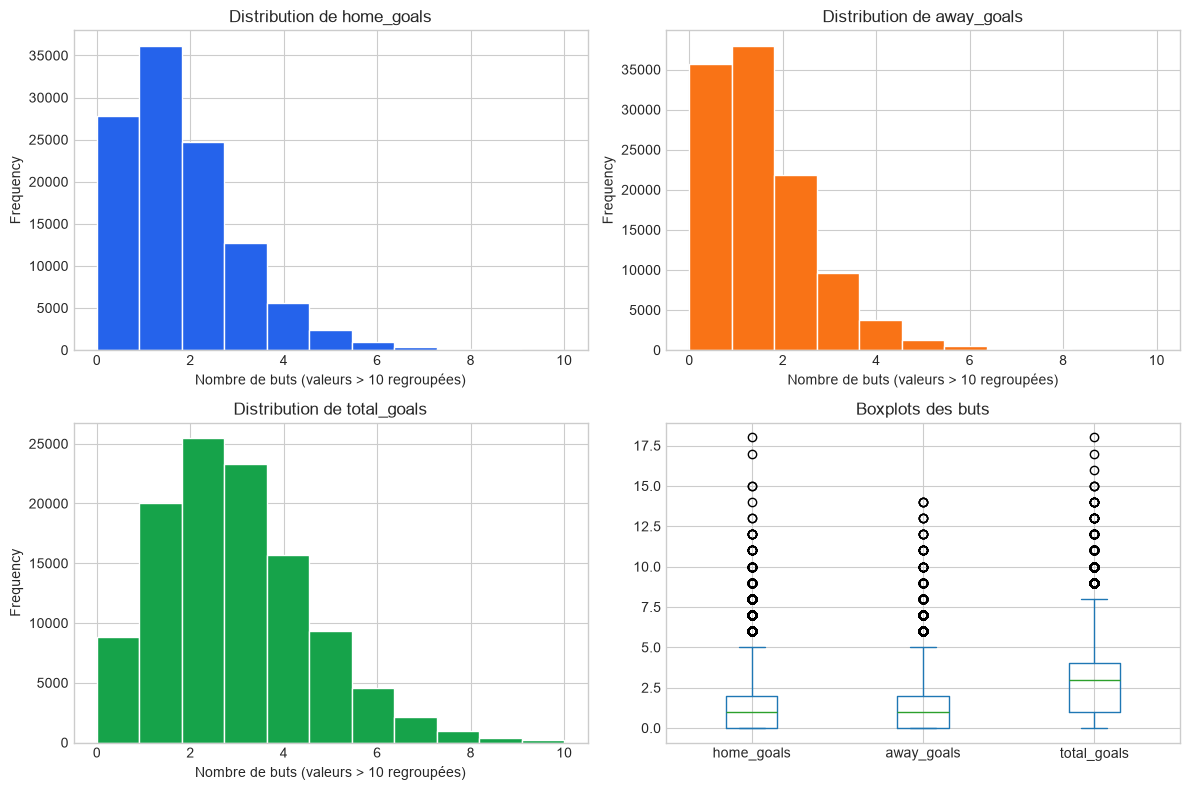

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = ["#2563eb", "#f97316", "#16a34a"]
for ax, column, color in zip(axes.flat[:3], ["home_goals", "away_goals", "total_goals"], colors):
    eda[column].clip(upper=10).plot(kind="hist", bins=11, ax=ax, color=color, edgecolor="white")
    ax.set_title(f"Distribution de {column}")
    ax.set_xlabel("Nombre de buts (valeurs > 10 regroupées)")
eda[["home_goals", "away_goals", "total_goals"]].plot(kind="box", ax=axes.flat[3])
axes.flat[3].set_title("Boxplots des buts")
plt.tight_layout()
plt.show()

## 3.2 Variables catégorielles

Effectifs, proportions et catégories rares.

In [23]:
target_counts = eda["target"].value_counts().reindex(["home", "draw", "away"])
target_analysis = pd.DataFrame({
    "effectif": target_counts,
    "proportion_pct": 100 * target_counts / target_counts.sum(),
})
league_counts = eda["league_name"].value_counts()
rare_leagues = league_counts[league_counts < 10]
display(target_analysis)
print(f"Ligues représentées : {league_counts.size:,}")
print(f"Ligues rares avec moins de 10 matchs : {rare_leagues.size:,}")
display(rare_leagues.head(20).to_frame("effectif"))

,effectif,proportion_pct
target,,
home,48113,43.37
draw,27651,24.92
away,35174,31.71


Ligues représentées : 727
Ligues rares avec moins de 10 matchs : 105


,effectif
league_name,
K-League Classic,9
Oberliga: Bayern Süd,9
Coppa Italia Serie C,9
Faroe Islands Cup,9
3. Lig Play-offs,9
Landesliga: Vorarlberg,9
3. HNL - North,9
Mtn 8 Cup,9
Cearense 2,9


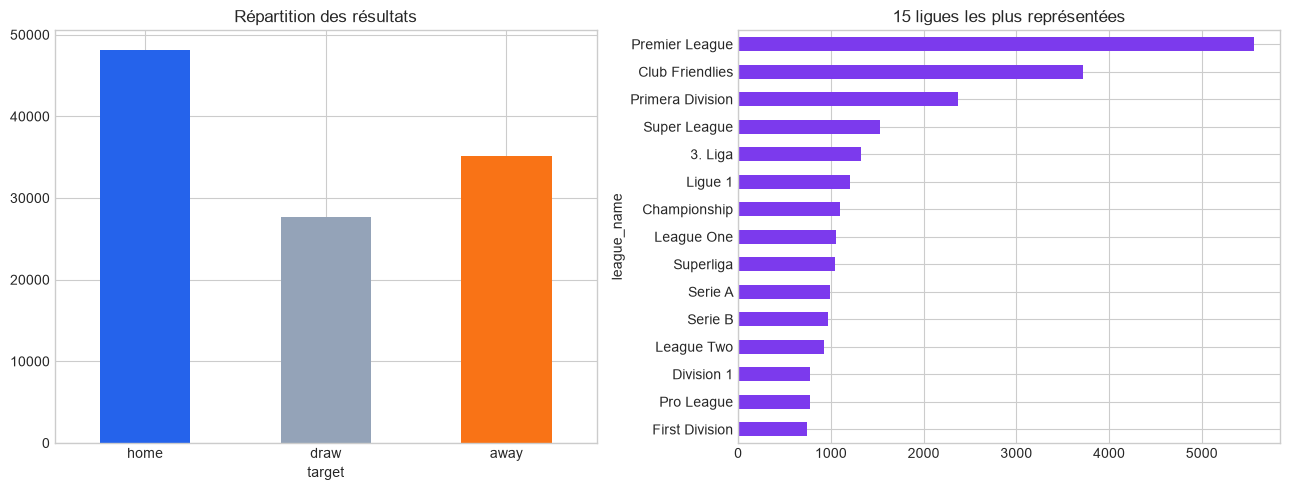

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
target_counts.plot(kind="bar", ax=axes[0], color=["#2563eb", "#94a3b8", "#f97316"])
axes[0].set_title("Répartition des résultats")
axes[0].tick_params(axis="x", rotation=0)
league_counts.head(15).sort_values().plot(kind="barh", ax=axes[1], color="#7c3aed")
axes[1].set_title("15 ligues les plus représentées")
plt.tight_layout()
plt.show()

## 3.3 Évolution dans le temps

Évolution du volume de matchs et des proportions de résultats. Une rupture brutale peut signaler un changement de couverture plutôt qu'un phénomène sportif.

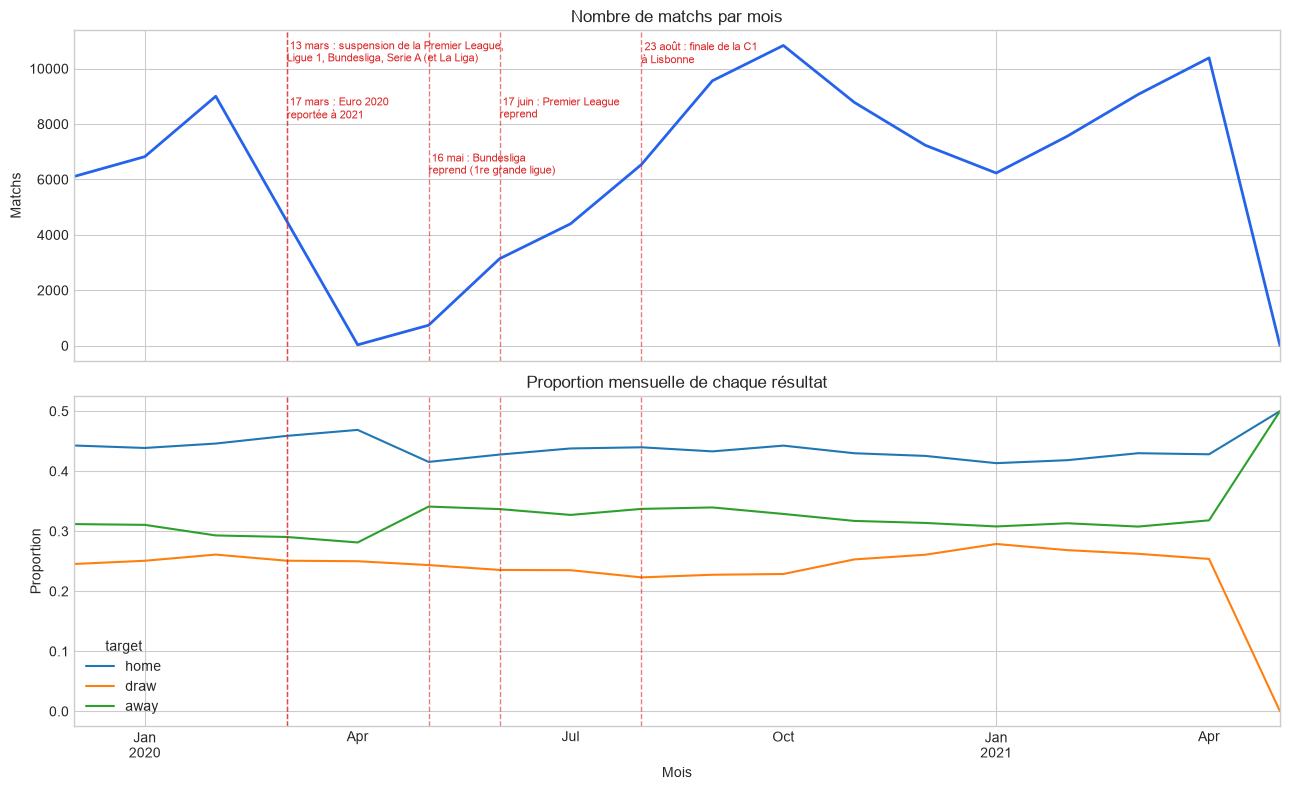

Période couverte : 2019-12-01 au 2021-05-01


In [ ]:
time_data = eda.dropna(subset=["match_date_parsed"]).copy()
monthly_matches = time_data.set_index("match_date_parsed").resample("ME").size()
monthly_target_share = (
    time_data.groupby([pd.Grouper(key="match_date_parsed", freq="ME"), "target"])
    .size()
    .unstack(fill_value=0)
)
monthly_target_share = monthly_target_share.div(monthly_target_share.sum(axis=1), axis=0)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
monthly_matches.plot(ax=axes[0], color="#2563eb", linewidth=2)
axes[0].set_title("Nombre de matchs par mois")
axes[0].set_ylabel("Matchs")
monthly_target_share[[c for c in ["home", "draw", "away"] if c in monthly_target_share]].plot(ax=axes[1])
axes[1].set_title("Proportion mensuelle de chaque résultat")
axes[1].set_ylabel("Proportion")

# Dates clés du COVID-19 et du football européen (les plus marquantes uniquement)
evenements = [
    ("2020-03-13", "13 mars : suspension de la Premier League,\nLigue 1, Bundesliga, Serie A et La Liga", 0.97),
    ("2020-03-17", "17 mars : Euro 2020\nreportée à 2021", 0.80),
    ("2020-05-16", "16 mai : Bundesliga\nreprend (1re grande ligue)", 0.63),
    ("2020-06-17", "17 juin : Premier League\nreprend", 0.80),
    ("2020-08-23", "23 août : finale de la C1\nà Lisbonne", 0.97),
]
for date, libelle, hauteur in evenements:
    date = pd.Timestamp(date)
    for ax in axes:
        ax.axvline(date, color="#dc2626", linestyle="--", linewidth=1, alpha=0.6)
    axes[0].text(
        date, hauteur, f" {libelle}",
        transform=axes[0].get_xaxis_transform(),
        fontsize=8, color="#dc2626", va="top",
    )
axes[0].set_xlabel("")
axes[1].set_xlabel("Mois")
plt.tight_layout()
plt.show()

print(f"Période couverte : {time_data['match_date_parsed'].min().date()} au {time_data['match_date_parsed'].max().date()}")

In [26]:
seasonality = time_data.assign(month=time_data["match_date_parsed"].dt.month).groupby("month").agg(
    matches=("id", "size"),
    average_total_goals=("total_goals", "mean"),
)
seasonality

,matches,average_total_goals
month,,
1,13055,2.65
2,16559,2.63
3,13568,2.61
4,10419,2.68
5,741,3.13
6,3138,2.99
7,4399,3.04
8,6540,3.03
9,9562,3.01


## 3.4 Comparaison de groupes avec `groupby()`

In [27]:
league_statistics = eda.groupby("league_name").agg(
    matches=("id", "size"),
    average_home_goals=("home_goals", "mean"),
    average_away_goals=("away_goals", "mean"),
    average_total_goals=("total_goals", "mean"),
)
result_by_league = pd.crosstab(eda["league_name"], eda["target"], normalize="index")
league_statistics = league_statistics.join(result_by_league).query("matches >= 100")
league_statistics.sort_values("matches", ascending=False).head(20)

,matches,average_home_goals,average_away_goals,average_total_goals,away,draw,home
league_name,,,,,,,
Premier League,5565,1.36,1.19,2.55,0.33,0.27,0.40
Club Friendlies,3724,1.86,1.43,3.29,0.31,0.23,0.46
Primera Division,2369,1.41,1.12,2.53,0.28,0.30,0.43
Super League,1530,1.40,1.09,2.49,0.29,0.29,0.43
3. Liga,1327,1.55,1.34,2.90,0.34,0.24,0.42
Ligue 1,1210,1.29,1.06,2.35,0.29,0.30,0.41
Championship,1097,1.32,1.17,2.49,0.34,0.26,0.40
League One,1050,1.37,1.18,2.55,0.32,0.26,0.42
Superliga,1048,1.40,1.20,2.60,0.32,0.26,0.42


## 3.5 Relations entre deux variables

Tableau croisé pour deux variables catégorielles, puis corrélations et scatterplot pour des variables numériques pertinentes.

target,away,draw,home
is_cup,,,
False,31.35,25.24,43.41
True,35.70,21.41,42.89


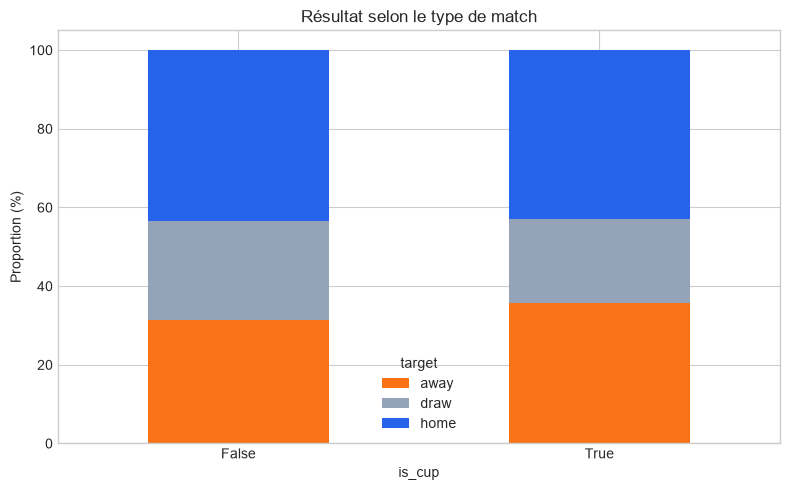

In [28]:
cup_target_crosstab = pd.crosstab(
    eda["is_cup"],
    eda["target"],
    normalize="index",
) * 100
display(cup_target_crosstab.round(2))
cup_target_crosstab.plot(kind="bar", stacked=True, figsize=(8, 5), color=["#f97316", "#94a3b8", "#2563eb"])
plt.title("Résultat selon le type de match")
plt.ylabel("Proportion (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,home_recent_goals_mean,away_recent_goals_mean,recent_rating_difference,home_goals,away_goals,total_goals
home_recent_goals_mean,1.00,0.18,0.39,0.21,-0.04,0.14
away_recent_goals_mean,0.18,1.00,-0.38,-0.05,0.19,0.09
recent_rating_difference,0.39,-0.38,1.00,0.25,-0.23,0.04
home_goals,0.21,-0.05,0.25,1.00,-0.08,0.72
away_goals,-0.04,0.19,-0.23,-0.08,1.00,0.63
total_goals,0.14,0.09,0.04,0.72,0.63,1.00


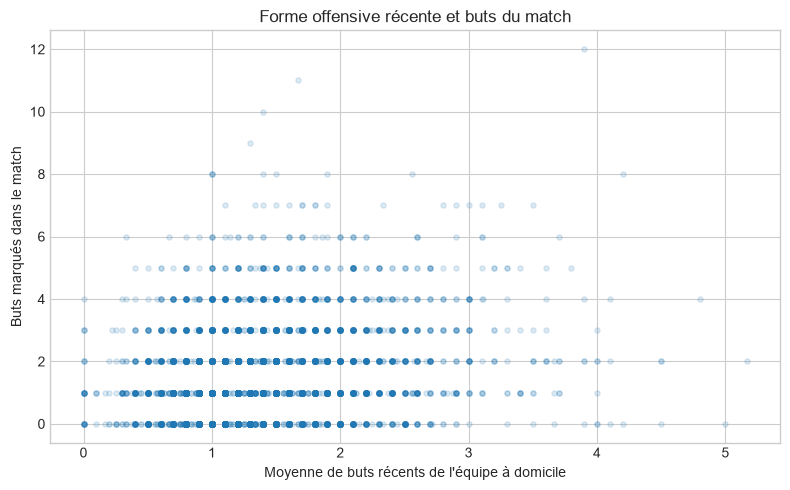

In [29]:
correlation_columns = [
    "home_recent_goals_mean", "away_recent_goals_mean",
    "recent_rating_difference", "home_goals", "away_goals", "total_goals",
]
correlations = eda[correlation_columns].corr()
display(correlations.round(3))

scatter_data = eda[["home_recent_goals_mean", "home_goals"]].dropna()
scatter_data = scatter_data.sample(min(5000, len(scatter_data)), random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(scatter_data["home_recent_goals_mean"], scatter_data["home_goals"], alpha=0.15, s=14)
plt.xlabel("Moyenne de buts récents de l'équipe à domicile")
plt.ylabel("Buts marqués dans le match")
plt.title("Forme offensive récente et buts du match")
plt.tight_layout()
plt.show()

In [30]:
paires = {
    "Domicile": ("home_recent_goals_mean", "home_goals"),
    "Extérieur": ("away_recent_goals_mean", "away_goals"),
}

resultats = []
for equipe, (historique, reel) in paires.items():
    donnees = eda[[historique, reel]].dropna()
    r = donnees[historique].corr(donnees[reel], method="pearson")
    resultats.append({
        "équipe": equipe,
        "n": len(donnees),
        "pearson_r": round(r, 4),
        "r2": round(r**2, 4),
    })

ensemble = pd.concat([
    eda[["home_recent_goals_mean", "home_goals"]].set_axis(["historique", "reel"], axis=1),
    eda[["away_recent_goals_mean", "away_goals"]].set_axis(["historique", "reel"], axis=1),
]).dropna()
r_total = ensemble["historique"].corr(ensemble["reel"], method="pearson")
resultats.append({"équipe": "Ensemble", "n": len(ensemble), "pearson_r": round(r_total, 4), "r2": round(r_total**2, 4)})

pd.DataFrame(resultats).set_index("équipe")

,n,pearson_r,r2
équipe,,,
Domicile,109779,0.21,0.04
Extérieur,109712,0.19,0.04
Ensemble,219491,0.20,0.04


### Matrice de corrélation

Pour visualiser d'un coup d'œil les relations entre les principales variables numériques, on calcule leur matrice de corrélation de Pearson et on la représente par une carte de chaleur. Les valeurs vont de −1 (relation négative parfaite) à +1 (relation positive parfaite) ; une valeur proche de 0 indique l'absence de relation linéaire.


,Buts récents dom.,Buts récents ext.,Note récente dom.,Note récente ext.,Écart de note récent,Buts dom. (match),Buts ext. (match),Buts totaux (match)
Buts récents dom.,1.00,0.18,0.68,0.25,0.39,0.21,-0.04,0.14
Buts récents ext.,0.18,1.00,0.25,0.67,-0.38,-0.05,0.19,0.09
Note récente dom.,0.68,0.25,1.00,0.40,0.55,0.24,-0.03,0.17
Note récente ext.,0.25,0.67,0.40,1.00,-0.54,-0.04,0.22,0.13
Écart de note récent,0.39,-0.38,0.55,-0.54,1.00,0.25,-0.23,0.04
Buts dom. (match),0.21,-0.05,0.24,-0.04,0.25,1.00,-0.08,0.72
Buts ext. (match),-0.04,0.19,-0.03,0.22,-0.23,-0.08,1.00,0.63
Buts totaux (match),0.14,0.09,0.17,0.13,0.04,0.72,0.63,1.00


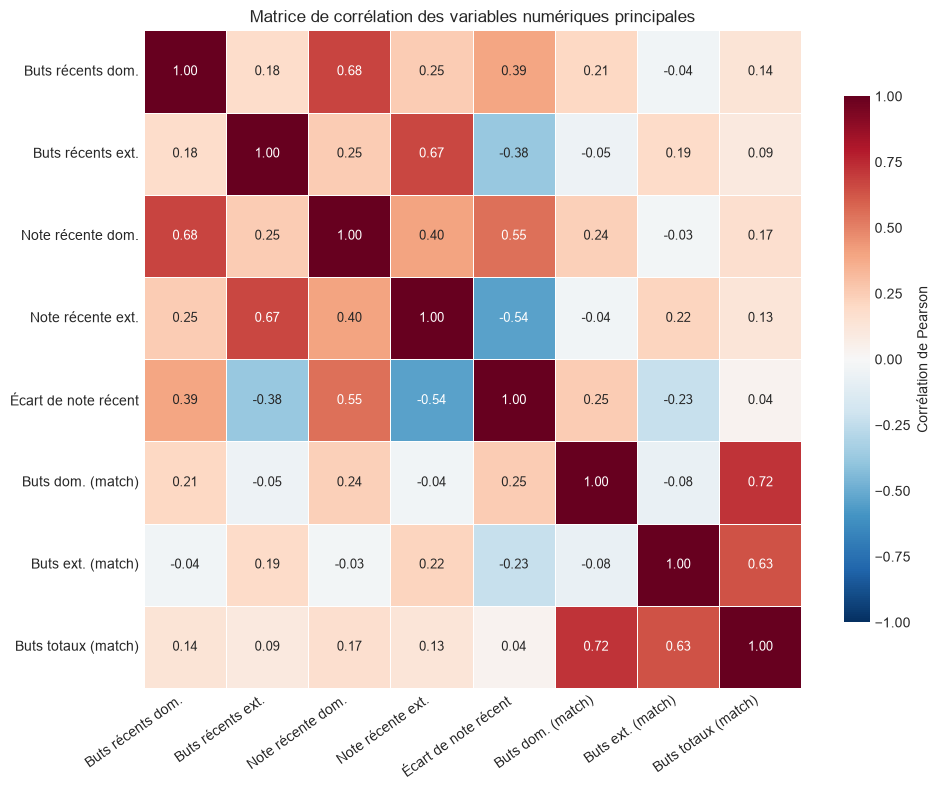

In [31]:
import seaborn as sns

variables_correlation = [
    "home_recent_goals_mean", "away_recent_goals_mean",
    "home_recent_rating_mean", "away_recent_rating_mean",
    "recent_rating_difference", "home_goals", "away_goals", "total_goals",
]
etiquettes = [
    "Buts récents dom.", "Buts récents ext.",
    "Note récente dom.", "Note récente ext.", "Écart de note récent",
    "Buts dom. (match)", "Buts ext. (match)", "Buts totaux (match)",
]

matrice = eda[variables_correlation].corr()
matrice.index = etiquettes
matrice.columns = etiquettes

display(matrice.round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(
    matrice,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 9},
    cbar_kws={"shrink": 0.8, "label": "Corrélation de Pearson"},
)
plt.title("Matrice de corrélation des variables numériques principales")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Lecture rapide :**

- Les corrélations les plus fortes sont en partie mécaniques : `home_goals` et `away_goals` avec `total_goals` (0,72 et 0,63), ainsi que les buts récents avec la note récente (0,68 à domicile, 0,67 à l'extérieur).
- La forme récente reste modérément liée aux buts du match : 0,19 à 0,25 pour les variables offensives, et −0,23 entre l'écart de note récent et les buts marqués par l'équipe à l'extérieur. Le signal est réel mais loin d'être déterministe.
- Les formes récentes à domicile et à l'extérieur ne sont corrélées qu'à 0,18 : il faut les traiter comme deux informations distinctes.
- `total_goals` est la somme de `home_goals` et `away_goals` ; sa forte corrélation avec ces deux variables est attendue et il ne faut pas l'utiliser en même temps qu'elles dans un modèle.


## Réponse à la partie 3 — Que racontent ces variables ?

### Reponse : les variables montrent un avantage du domicile, une forte hétérogénéité entre ligues et des relations prédictives réelles mais modérées.

- Résultats : domicile 43.37%, nul 24.92%, extérieur 31.71%.
- Buts moyens : 1.52 à domicile, 1.24 à l'extérieur, 2.76 au total.
- Couverture : 727 ligues, dont 105 avec moins de 10 matchs; les comparaisons doivent donc tenir compte de la ligue.
- La forme offensive récente est corrélée à 0.209 avec les buts du match à domicile.
- La différence de rating récent est corrélée à 0.252 avec les buts à domicile.
- La couverture varie dans le temps : l'évaluation du modéle devra donc être chronologique.
- Ces relations sont utiles pour prédire, mais une corrélation ne prouve pas une causalité.



# Partie 4 — Question

Question: *Dans quelle mesure les performances récentes d’une équipe influencent-elles son prochain résultat, indépendamment de son niveau habituel et de la force des adversaires rencontrés ?*

## 4.1 Construction des variables

Pour suivre une équipe, chaque match est transformé en **deux observations** : une pour l'équipe à domicile, une pour l'équipe à l'extérieur. La variable expliquée est le nombre de points gagnés au match suivant (3, 1 ou 0).

On distingue deux fenêtres dans l'historique :

- **forme récente** : les matchs `_1` à `_5`, résumés par les points par match et la différence de buts ;
- **niveau habituel** : les matchs `_6` à `_10`, résumés par la note moyenne. Les deux fenêtres ne se chevauchent pas, ce qui évite de faire entrer la forme récente dans la mesure du niveau.

La **force des adversaires** est approchée par la note moyenne des adversaires rencontrés pendant les 5 derniers matchs, et par le niveau habituel de l'adversaire du match suivant. On exige au moins 3 matchs valides dans chaque fenêtre.


In [32]:
import numpy as np
from scipy import stats

RECENT = range(1, 6)   # les 5 derniers matchs : forme récente
OLDER = range(6, 11)   # les 5 matchs précédents : niveau habituel


def resume_historique(prefixe, slots):
    """Résume un bloc de matchs d'un historique : résultats, différence et notes."""
    buts = eda[[f"{prefixe}_history_goal_{i}" for i in slots]].to_numpy(dtype=float)
    encaisses = eda[[f"{prefixe}_history_opponent_goal_{i}" for i in slots]].to_numpy(dtype=float)
    notes = eda[[f"{prefixe}_history_rating_{i}" for i in slots]].to_numpy(dtype=float)
    notes_adverses = eda[[f"{prefixe}_history_opponent_rating_{i}" for i in slots]].to_numpy(dtype=float)

    valides = ~np.isnan(buts) & ~np.isnan(encaisses)
    points = np.where(buts > encaisses, 3.0, np.where(buts == encaisses, 1.0, 0.0))
    points = np.where(valides, points, np.nan)
    difference = np.where(valides, buts - encaisses, np.nan)

    def moyenne(valeurs):
        with np.errstate(invalid="ignore"):
            resultat = np.nanmean(valeurs, axis=1)
        return np.where(np.sum(~np.isnan(valeurs), axis=1) > 0, resultat, np.nan)

    return pd.DataFrame({
        "matchs": valides.sum(axis=1),
        "points": moyenne(points),
        "difference": moyenne(difference),
        "notes": (~np.isnan(notes)).sum(axis=1),
        "note": moyenne(notes),
        "notes_adverses": (~np.isnan(notes_adverses)).sum(axis=1),
        "note_adverse": moyenne(notes_adverses),
    }, index=eda.index)


def table_equipe(prefixe, autre, colonne_equipe, colonne_adversaire,
                 points_suivant, difference_suivante, domicile):
    """Construit une ligne par équipe et par match, avec sa forme et son niveau."""
    recent = resume_historique(prefixe, RECENT)
    ancien = resume_historique(prefixe, OLDER)
    recent_adverse = resume_historique(autre, RECENT)
    ancien_adverse = resume_historique(autre, OLDER)

    return pd.DataFrame({
        "match_id": eda["id"],
        "date": eda["match_date_parsed"],
        "ligue": eda["league_name"],
        "equipe": eda[colonne_equipe],
        "adversaire": eda[colonne_adversaire],
        "domicile": domicile,
        "points_suivant": points_suivant,
        "difference_suivante": difference_suivante,
        "forme_points": recent["points"],
        "forme_difference": recent["difference"],
        "forme_note": recent["note"],
        "adversaires_recents": recent["note_adverse"],
        "niveau": ancien["note"],
        "niveau_points": ancien["points"],
        "niveau_adversaire": ancien_adverse["note"],
        "forme_adversaire": recent_adverse["points"],
        "n_recent": recent["matchs"],
        "n_recent_notes": recent["notes"],
        "n_recent_adv": recent["notes_adverses"],
        "n_ancien": ancien["matchs"],
        "n_ancien_notes": ancien["notes"],
        "n_adv_ancien": ancien_adverse["matchs"],
        "n_adv_ancien_notes": ancien_adverse["notes"],
    })


domicile = table_equipe(
    "home_team", "away_team", "home_team_name", "away_team_name",
    eda["target"].map({"home": 3, "draw": 1, "away": 0}),
    eda["home_goals"] - eda["away_goals"],
    1,
)
exterieur = table_equipe(
    "away_team", "home_team", "away_team_name", "home_team_name",
    eda["target"].map({"home": 0, "draw": 1, "away": 3}),
    eda["away_goals"] - eda["home_goals"],
    0,
)
equipes = pd.concat([domicile, exterieur], ignore_index=True)

colonnes_requises = [
    "points_suivant", "difference_suivante",
    "forme_points", "forme_difference", "forme_note", "adversaires_recents",
    "niveau", "niveau_points", "niveau_adversaire", "forme_adversaire",
]
equipes = equipes.dropna(subset=colonnes_requises)
equipes = equipes[
    (equipes["n_recent"] >= 3) & (equipes["n_recent_notes"] >= 3) & (equipes["n_recent_adv"] >= 3)
    & (equipes["n_ancien"] >= 3) & (equipes["n_ancien_notes"] >= 3)
    & (equipes["n_adv_ancien"] >= 3) & (equipes["n_adv_ancien_notes"] >= 3)
]
equipes = equipes.sort_values(["date", "match_id"]).reset_index(drop=True)

print(
    f"{len(equipes):,} observations équipe-match, "
    f"{equipes['match_id'].nunique():,} matchs et {equipes['equipe'].nunique():,} équipes."
)
print(f"Points au match suivant : {equipes['points_suivant'].mean():.2f} en moyenne.")
display(
    equipes[[
        "points_suivant", "forme_points", "forme_note", "adversaires_recents",
        "niveau", "niveau_adversaire", "forme_adversaire",
    ]].describe().round(2)
)


/var/folders/h7/9sthllt14n59j8j_0ydw0c2r0000gp/T/ipykernel_84238/3108876157.py:22: RuntimeWarning: Mean of empty slice
  resultat = np.nanmean(valeurs, axis=1)


190,624 observations équipe-match, 95,312 matchs et 8,188 équipes.
Points au match suivant : 1.37 en moyenne.


,points_suivant,forme_points,forme_note,adversaires_recents,niveau,niveau_adversaire,forme_adversaire
count,"190,624.00","190,624.00","190,624.00","190,624.00","190,624.00","190,624.00","190,624.00"
mean,1.37,1.39,6.52,6.37,6.53,6.53,1.39
std,1.31,0.67,1.88,1.74,1.87,1.87,0.67
min,0.00,0.00,2.28,2.23,2.28,2.28,0.00
25%,0.00,0.80,5.23,5.20,5.26,5.26,0.80
50%,1.00,1.40,6.11,6.05,6.13,6.13,1.40
75%,3.00,1.80,7.35,7.15,7.35,7.35,1.80
max,3.00,3.00,27.88,27.98,32.95,32.95,3.00


## 4.2 La forme récente brute est associée au résultat suivant

On commence par la relation la plus simple, sans aucun contrôle : les points du match suivant augmentent-ils avec la forme récente ?


Corrélation globale forme récente / résultat suivant : 0.142


,moyenne,effectif
forme_points,,
"(-0.001, 0.8]",1.15,48574
"(0.8, 1.2]",1.29,37115
"(1.2, 1.6]",1.39,42451
"(1.6, 2.0]",1.50,34857
"(2.0, 3.0]",1.69,27627


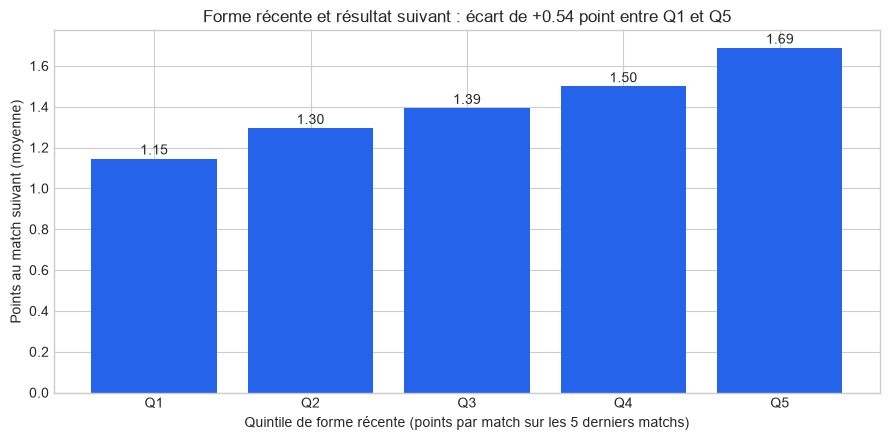

In [33]:
correlation_brute = equipes["forme_points"].corr(equipes["points_suivant"])
quintiles = pd.qcut(equipes["forme_points"], 5, duplicates="drop")
forme_brute = equipes.groupby(quintiles, observed=True)["points_suivant"].agg(
    moyenne="mean", effectif="count"
)

print(f"Corrélation globale forme récente / résultat suivant : {correlation_brute:.3f}")
display(forme_brute.round(3))

ecart_brut = forme_brute["moyenne"].iloc[-1] - forme_brute["moyenne"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(len(forme_brute)), forme_brute["moyenne"], color="#2563eb")
ax.set_xticks(range(len(forme_brute)))
ax.set_xticklabels([f"Q{i + 1}" for i in range(len(forme_brute))])
for i, valeur in enumerate(forme_brute["moyenne"]):
    ax.text(i, valeur + 0.02, f"{valeur:.2f}", ha="center")
ax.set_xlabel("Quintile de forme récente (points par match sur les 5 derniers matchs)")
ax.set_ylabel("Points au match suivant (moyenne)")
ax.set_title(f"Forme récente et résultat suivant : écart de {ecart_brut:+.2f} point entre Q1 et Q5")
plt.tight_layout()
plt.show()


## 4.3 Contrôler le niveau habituel et la force des adversaires

La relation précédente peut venir du fait que les bonnes équipes ont à la fois une bonne forme et de bons résultats. On ajoute donc le niveau habituel de l'équipe, le niveau de l'adversaire, sa forme récente et la force des adversaires déjà rencontrés. Les coefficients sont standardisés : ils mesurent l'effet d'un écart-type et sont donc comparables entre variables.


In [34]:
def regression_robuste(donnees, cible, variables, grappe):
    """MCO avec erreurs standard regroupées par grappe (match ou équipe)."""
    d = donnees.dropna(subset=[cible] + variables).copy()
    X = np.column_stack([np.ones(len(d))] + [d[v].to_numpy(dtype=float) for v in variables])
    y = d[cible].to_numpy(dtype=float)

    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    residus = y - X @ beta
    XtX_inv = np.linalg.inv(X.T @ X)

    scores = pd.DataFrame(X * residus[:, None])
    scores["grappe"] = d[grappe].to_numpy()
    meat = scores.groupby("grappe").sum().to_numpy()

    n, k = X.shape
    G = scores["grappe"].nunique()
    correction = (G / (G - 1)) * ((n - 1) / (n - k))
    covariance = correction * XtX_inv @ (meat.T @ meat) @ XtX_inv
    erreur = np.sqrt(np.diag(covariance))
    t_stat = beta / erreur
    p_valeur = 2 * stats.t.sf(np.abs(t_stat), G - 1)
    r2 = 1 - (residus @ residus) / ((y - y.mean()) @ (y - y.mean()))

    return pd.DataFrame({
        "variable": ["constante"] + variables,
        "coef": beta,
        "erreur": erreur,
        "t": t_stat,
        "p": p_valeur,
        "ic_bas": beta - 1.96 * erreur,
        "ic_haut": beta + 1.96 * erreur,
    }), r2, n


# Les coefficients sont standardisés : un coefficient = l'effet d'un écart-type.
donnees_z = equipes.copy()
continues = [
    "forme_points", "forme_note", "niveau", "niveau_adversaire",
    "adversaires_recents", "forme_adversaire",
]
for colonne in continues:
    donnees_z[colonne] = (donnees_z[colonne] - donnees_z[colonne].mean()) / donnees_z[colonne].std()

modeles = {
    "M1 : forme seule": ["forme_points"],
    "M2 : + niveau et adversaire": ["forme_points", "niveau", "niveau_adversaire", "domicile"],
    "M3 : + adversaires récents": [
        "forme_points", "niveau", "niveau_adversaire", "domicile",
        "adversaires_recents", "forme_adversaire",
    ],
}

lignes = []
for nom, variables in modeles.items():
    tableau, r2, n = regression_robuste(donnees_z, "points_suivant", variables, "match_id")
    effet = tableau.set_index("variable").loc["forme_points"]
    lignes.append({
        "modèle": nom,
        "coef_forme": effet["coef"],
        "erreur": effet["erreur"],
        "p": effet["p"],
        "R2": r2,
        "n": n,
    })

print("Effet de la forme récente sur les points du match suivant,")
print("coefficients standardisés (pour un écart-type de forme) :")
display(pd.DataFrame(lignes).set_index("modèle").round(4))

tableau_m3, r2_m3, n_m3 = regression_robuste(
    donnees_z, "points_suivant", modeles["M3 : + adversaires récents"], "match_id"
)
print("Modèle complet M3 (toutes les variables sont standardisées) :")
display(tableau_m3.round(3))


Effet de la forme récente sur les points du match suivant,
coefficients standardisés (pour un écart-type de forme) :


,coef_forme,erreur,p,R2,n
modèle,,,,,
M1 : forme seule,0.19,0.00,0.00,0.02,190624
M2 : + niveau et adversaire,0.13,0.00,0.00,0.08,190624
M3 : + adversaires récents,0.10,0.00,0.00,0.09,190624


Modèle complet M3 (toutes les variables sont standardisées) :


,variable,coef,erreur,t,p,ic_bas,ic_haut
0,constante,1.20,0.00,298.84,0.00,1.19,1.21
1,forme_points,0.10,0.00,31.75,0.00,0.10,0.11
2,niveau,0.21,0.00,57.80,0.00,0.21,0.22
3,niveau_adversaire,-0.17,0.00,-44.10,0.00,-0.17,-0.16
4,domicile,0.35,0.01,44.16,0.00,0.34,0.37
5,adversaires_recents,-0.09,0.00,-35.84,0.00,-0.09,-0.08
6,forme_adversaire,-0.16,0.00,-51.32,0.00,-0.16,-0.15


## 4.4 Comparer chaque équipe à elle-même

Le contrôle précédent reste imparfait : la note moyenne des matchs `_6` à `_10` mesure le niveau avec du bruit. Pour aller plus loin, on compare chaque équipe à sa propre moyenne (effets fixes d'équipe). Cette fois, seules les variations **à l'intérieur d'une même équipe** sont utilisées : si la forme récente a un effet propre, il doit apparaître ici.


In [ ]:
# Comparer chaque équipe à elle-même : on retire la moyenne de chaque équipe.
donnees_within = donnees_z.copy()
for colonne in ["points_suivant", "domicile"] + continues:
    donnees_within[colonne + "_w"] = (
        donnees_within[colonne]
        - donnees_within.groupby("equipe")[colonne].transform("mean")
    )

tableau_within, r2_within, n_within = regression_robuste(
    donnees_within,
    "points_suivant_w",
    ["forme_points_w", "adversaires_recents_w", "niveau_adversaire_w",
     "forme_adversaire_w", "domicile_w"],
    "equipe",
)
print("Même modèle, mais en comparant chaque équipe à sa propre moyenne :")
display(tableau_within.round(3))

# Gradient à l'intérieur des équipes.
forme_centree = equipes["forme_points"] - equipes.groupby("equipe")["forme_points"].transform("mean")
quintiles_centres = pd.qcut(forme_centree, 5, duplicates="drop")
forme_within = equipes.groupby(quintiles_centres, observed=True)["points_suivant"].agg(
    moyenne="mean", effectif="count"
)
display(forme_within.round(3))

ecart_within = forme_within["moyenne"].iloc[-1] - forme_within["moyenne"].iloc[0]
correlation_within = forme_centree.corr(equipes["points_suivant"])
correlation_entre = (
    equipes.groupby("equipe")[["forme_points", "points_suivant"]]
    .mean()
    .corr()
    .loc["forme_points", "points_suivant"]
)

print(f"Corrélation entre équipes : {correlation_entre:.3f}")
print(f"Corrélation à l'intérieur des équipes : {correlation_within:.3f}")
print(f"Écart Q1-Q5 de la forme centrée : {ecart_within:+.3f} point")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(len(forme_within)), forme_within["moyenne"], color="#f97316")
ax.set_xticks(range(len(forme_within)))
ax.set_xticklabels([f"Q{i + 1}" for i in range(len(forme_within))])
ax.axhline(
    equipes["points_suivant"].mean(), color="gray", linestyle="--", linewidth=1,
    label="moyenne générale",
)
ax.set_xlabel("Quintile de forme centrée sur la moyenne de l'équipe")
ax.set_ylabel("Points au match suivant (moyenne)")
ax.set_title(f"À l'intérieur d'une équipe, le gradient disparaît ({ecart_within:+.2f} point)")
ax.legend()
plt.tight_layout()
plt.show()


## Réponse à la partie 4 — Dans quelle mesure la forme récente influence-t-elle le résultat suivant ?

**RÉPONSE : très peu, et probablement pas de façon causale.**

- **Sans contrôle**, la forme récente est clairement associée au résultat suivant : on passe de **1,15 point** au match suivant dans le quintile de forme le plus bas à **1,69 point** dans le plus haut, soit **+0,54 point**. La corrélation brute est de **0,14**.
- **En contrôlant le niveau habituel et la force des adversaires**, l'effet diminue de moitié : le coefficient standardisé de la forme passe de **0,186** (modèle M1) à **0,133** (M2), puis à **0,103** (M3). En points, passer de 0 à 3 points de forme récente est associé à **+0,46 point** au match suivant. Le niveau habituel (**0,213**), le niveau de l'adversaire (**−0,166**) et sa forme récente (**−0,156**) pèsent davantage.
- **En comparant chaque équipe à elle-même**, le gradient disparaît : le coefficient de la forme devient **−0,052** (léger retour à la moyenne), et l'écart entre le quintile de forme centrée le plus bas et le plus haut est de **−0,13 point**. La corrélation entre équipes est de **0,69**, contre **−0,04** à l'intérieur des équipes.

Autrement dit, l'association brute vient surtout du fait que les **bonnes équipes** ont à la fois de bons résultats récents et de bons résultats à venir. Une fois le niveau habituel et la qualité des adversaires pris en compte, la forme récente n'ajoute qu'un signal marginal ; elle peut même traduire un simple **retour à la moyenne** après une série exceptionnelle. Il s'agit d'associations observées, pas d'une preuve de causalité.
